# Giorno 4, pomeriggio: random forest, validazione e overfitting

Obiettivo: addestrare un classificatore, stimarne onestamente le prestazioni, e vedere
con i vostri occhi come un modello arrivi al 100 % di accuratezza su puro rumore.

In un pomeriggio non si impara il machine learning. Si impara però a non farsi ingannare
dai numeri che produce: quelli di un software, di un articolo, o i propri.

## 0. Cella di avvio

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

def trova_dati():
    for cand in [Path("../dati"), Path("dati"), Path("corso_python_CNR/dati")]:
        if cand.exists():
            return cand
    for radice in [Path(".."), Path("."), Path("corso_python_CNR")]:
        if (radice / "genera_dati.py").exists():
            sys.path.insert(0, str(radice.resolve()))
            from genera_dati import genera_tutto
            return genera_tutto(radice / "dati")
    raise FileNotFoundError("Cartella 'dati' non trovata: carica la cartella del corso.")

DATI = trova_dati()
mpl.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
from cycler import cycler
mpl.rcParams["axes.prop_cycle"] = cycler(color=["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00"])

from sklearn.model_selection import (train_test_split, cross_val_score, StratifiedKFold, RepeatedStratifiedKFold,
                                     StratifiedGroupKFold,
                                     cross_val_predict, permutation_test_score)
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

df = pd.read_csv(DATI / "sensori_matrice.csv")
variabili = [c for c in df.columns if c not in ("campione", "classe")]
X = df[variabili]
y = df["classe"]
print(X.shape, y.value_counts().to_dict())

(60, 20) {'Cascine': 20, 'Vallombrosa': 20, 'Maremma': 20}


---
## 1. Supervisionato: la domanda cambia

Stamattina la domanda era: c'è struttura? Adesso è: dato un campione nuovo, di che sito è? Abbiamo le
etichette (`y`) e vogliamo un modello che le preveda dalle misure (`X`).

### Random forest, in due paragrafi

Un **albero di decisione** è una sequenza di domande sulle variabili ("la corrente a −0.25 V
è > 2.1?") che porta a una classe. Da solo è instabile: cambia molto al cambiare di pochi
campioni.

Una **random forest** ne addestra centinaia, ognuno su un ricampionamento dei dati e su un
sottoinsieme casuale delle variabili, e fa votare. Perché la usiamo qui: funziona senza
standardizzazione, gestisce variabili di natura diversa, ha pochi parametri da regolare, e dà
una misura dell'importanza di ogni variabile. Perché non basta: con 60 campioni qualunque
modello può imparare a memoria, ed è qui che serve la validazione.

#### Nota per il docente: i tempi del pomeriggio

Sezioni 1-5 in circa 90', poi il progetto (60') e la chiusura (15'). Le parti segnate *Facoltativo*
nella sezione 6 si saltano senza problemi. Regola pratica: **se alle 15:30 non avete finito la
sezione 4, passate direttamente al progetto** (la sezione 5 si recupera a voce nel progetto, punto 4).

---
## 2. Train e test

Il modello si **addestra su una parte** dei dati e si **valuta su un'altra che non ha mai
visto**. È una regola senza eccezioni. Valutarlo sugli stessi dati di addestramento misura la memoria, non la capacità
di generalizzare.

`train_test_split` con `stratify=y` mantiene le proporzioni delle classi; `random_state`
rende la divisione riproducibile.

In [2]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
print(f"train: {len(X_tr)}  test: {len(X_te)}")
print(y_te.value_counts().to_dict())

train: 42  test: 18
{'Vallombrosa': 6, 'Maremma': 6, 'Cascine': 6}


In [3]:
# Le random forest recenti accettano i NaN, ma molti altri modelli no: imputiamo, così lo schema vale per tutti.
imp = SimpleImputer(strategy="median").fit(X_tr)         # fit SOLO sul train
X_tr_i = imp.transform(X_tr)
X_te_i = imp.transform(X_te)

rf = RandomForestClassifier(n_estimators=300, random_state=0)
rf.fit(X_tr_i, y_tr)
print(f"accuratezza sul TRAIN: {accuracy_score(y_tr, rf.predict(X_tr_i)):.3f}")
print(f"accuratezza sul TEST:  {accuracy_score(y_te, rf.predict(X_te_i)):.3f}")

accuratezza sul TRAIN: 1.000
accuratezza sul TEST:  1.000


Sul train è 1.000, e per una random forest lo è sempre: non dice niente. Il numero che conta è
quello sul test. Ma con 18 campioni di test, un campione sbagliato vale 5.6 punti
percentuali: la stima è grossolana, e dipende da *quali* 18 sono finiti nel test.

In [4]:
# Quanto dipende dalla divisione? Ripetiamo con 10 semi diversi
acc = []
for seme in range(10):
    a, b, c, d = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seme)
    im = SimpleImputer(strategy="median").fit(a)
    m = RandomForestClassifier(n_estimators=300, random_state=0).fit(im.transform(a), c)
    acc.append(accuracy_score(d, m.predict(im.transform(b))))
print("accuratezza sul test per 10 divisioni diverse:", np.round(acc, 3))
print(f"media {np.mean(acc):.3f}, min {np.min(acc):.3f}, max {np.max(acc):.3f}")

accuratezza sul test per 10 divisioni diverse: [1.    0.889 0.889 1.    1.    0.778 0.889 0.944 0.944 1.   ]
media 0.933, min 0.778, max 1.000


---
## 3. Validazione crociata (k-fold)

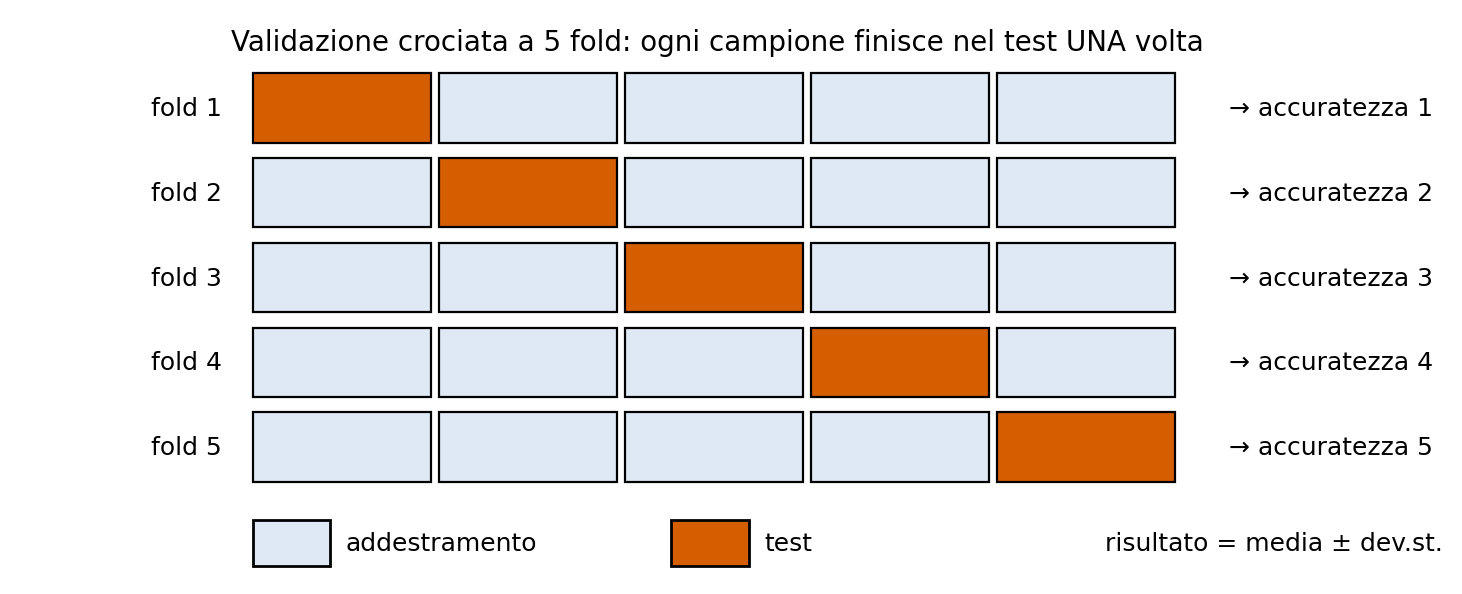

Si divide il dataset in $k$ parti; a turno una fa da test e le altre da train. Ogni campione
viene testato una volta sola. Si riporta **media ± deviazione standard** delle $k$
accuratezze: la deviazione standard dice quanto è stabile il risultato. `StratifiedKFold` mantiene le
proporzioni di classe in ogni fold.

Come si sceglie k con pochi campioni: $k = 5$ è il default ragionevole: ogni fold di test
ha ancora abbastanza campioni (12 su 60) per dare un numero sensato. $k = 10$ quando i
campioni sono più di ~100. *Leave-one-out* ($k = n$) usa quasi tutti i dati per addestrare ma
dà stime molto variabili, non si può stratificare e costa $n$ addestramenti; con 20-30 campioni
di solito conviene una k-fold ripetuta (la usiamo nella sezione 4).
Con classi piccole (< 5 campioni per classe) nessuna CV è affidabile: ditelo, non nascondetelo.
Qualunque $k$: se il risultato cambia molto cambiando `random_state`, riportate la media su
più ripetizioni (`RepeatedStratifiedKFold`), come faremo fra poco.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
modello = Pipeline([("imputer", SimpleImputer(strategy="median")),
                    ("rf", RandomForestClassifier(n_estimators=300, random_state=0))])
punteggi = cross_val_score(modello, X, y, cv=cv, scoring="accuracy")
print("accuratezza per fold:", np.round(punteggi, 3))
print(f"CV 5-fold: {punteggi.mean():.3f} ± {punteggi.std():.3f}")

accuratezza per fold: [1.    0.75  0.917 0.917 1.   ]
CV 5-fold: 0.917 ± 0.091


> In sintesi: *accuratezza 0.92 ± 0.09 (validazione crociata stratificata a 5 fold, n = 60)*.
> Un'accuratezza senza il metodo con cui è stata misurata non dice molto.

### Esercizio 8.1: quanto è stabile la CV? (livello 1, 5')

Rifate la stessa validazione crociata cambiando due cose, una alla volta:
1. `random_state=1` invece di 0 (cioè un'altra divisione in 5 fold);
2. `n_splits=10` invece di 5.

Stampate media ± sd in entrambi i casi. La media cambia di molto? E la sd?

In [6]:
# ESERCIZIO 8.1 (livello 1)
#> cv_1 = StratifiedKFold(n_splits=5, shuffle=True, random_state=____)
#> p_1 = cross_val_score(modello, X, y, cv=____, scoring="accuracy")
#> print(f"5 fold, altro seme: {p_1.mean():.3f} ± {p_1.std():.3f}")
#>
#> cv_10 = StratifiedKFold(n_splits=____, shuffle=True, random_state=0)
#> p_10 = cross_val_score(modello, X, y, cv=cv_10, scoring="accuracy")
#> print(f"10 fold:            {p_10.mean():.3f} ± {p_10.std():.3f}")
# --- SOLUZIONE ---
cv_1 = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
p_1 = cross_val_score(modello, X, y, cv=cv_1, scoring="accuracy")
print(f"5 fold, altro seme: {p_1.mean():.3f} ± {p_1.std():.3f}")

cv_10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
p_10 = cross_val_score(modello, X, y, cv=cv_10, scoring="accuracy")
print(f"10 fold:            {p_10.mean():.3f} ± {p_10.std():.3f}")
# Commento: la media si sposta di qualche punto, la sd cambia di più (con 10 fold ogni test ha solo
# 6 campioni, quindi ogni fold è più rumoroso). Si riporta il metodo insieme al numero, e se il numero
# dipende dal seme si fa la media su più ripetizioni (RepeatedStratifiedKFold, sezione 4).

5 fold, altro seme: 0.933 ± 0.082


10 fold:            0.917 ± 0.201


---
## 4. Overfitting dal vivo: 100 % di accuratezza su puro rumore

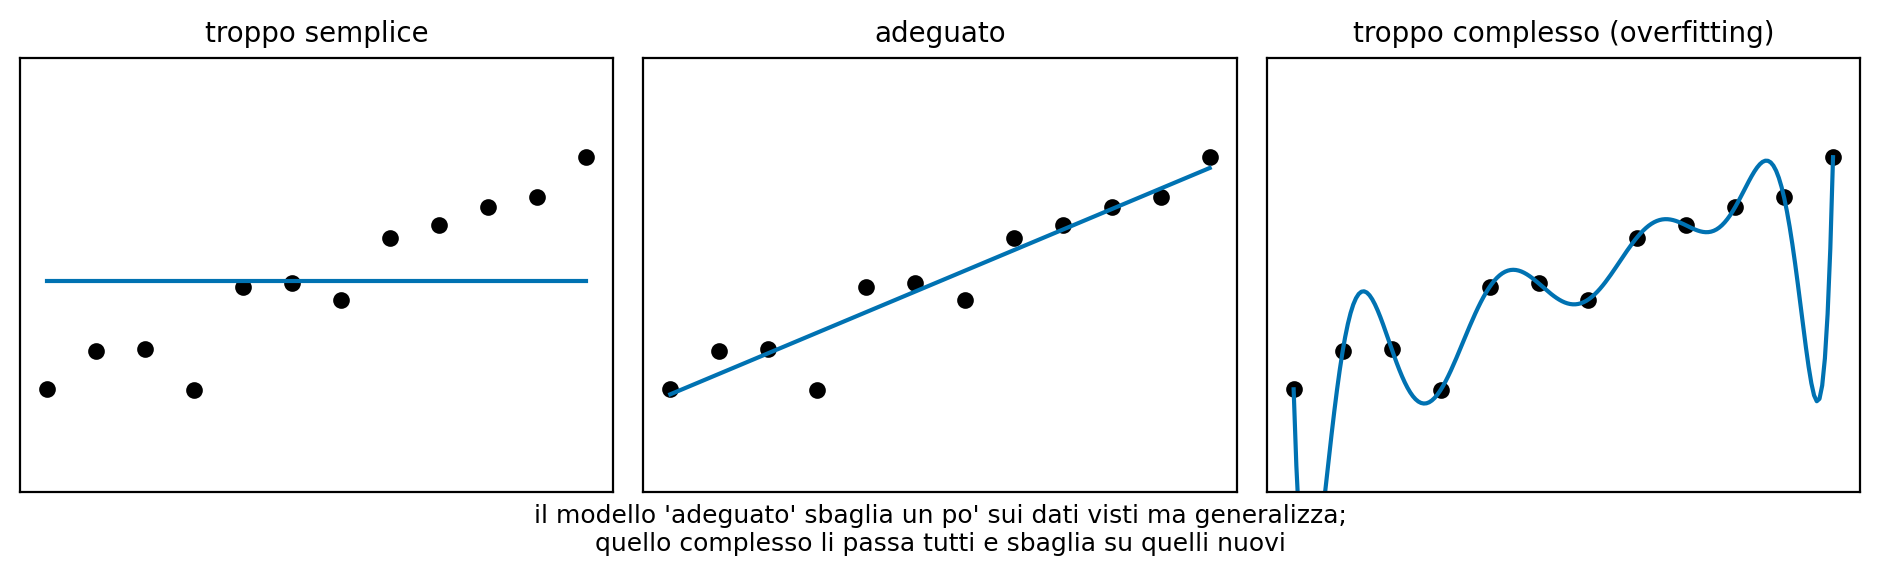

Se dovete ricordare una sola sezione del corso, ricordate questa. `rumore_puro.csv` ha 30
campioni e 200 variabili generate a caso, con un'etichetta 0/1 (15 e 15) senza alcun legame con
le variabili: non c'è niente da imparare. Guardate cosa succede.

In [7]:
rum = pd.read_csv(DATI / "rumore_puro.csv")
Xr = rum.drop(columns="classe")
yr = rum["classe"]
print(Xr.shape, yr.value_counts().to_dict())

# Passo 1: modello addestrato e valutato sugli stessi dati
rf_r = RandomForestClassifier(n_estimators=300, random_state=0).fit(Xr, yr)
print(f"accuratezza sul train (rumore puro): {accuracy_score(yr, rf_r.predict(Xr)):.2f}   <- 'perfetto'")

(30, 200) {0: 15, 1: 15}


accuratezza sul train (rumore puro): 1.00   <- 'perfetto'


In [8]:
# Passo 2: la stessa cosa in validazione crociata.
# Con 30 campioni una singola divisione in 5 fold è molto rumorosa (6 campioni per test):
# la ripetiamo 10 volte con divisioni diverse e facciamo la media (RepeatedStratifiedKFold).
cv_r = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
p = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=0), Xr, yr, cv=cv_r)
print(f"accuratezza in CV (rumore puro): {p.mean():.2f} ± {p.std():.2f}   <- il caso: ~0.5")

accuratezza in CV (rumore puro): 0.51 ± 0.16   <- il caso: ~0.5


La CV ha fatto il suo lavoro: 0.5 è il lancio di una moneta. Ora l'errore più sottile, e molto
diffuso: selezionare le variabili "migliori" guardando tutti i dati, e solo
dopo fare la validazione crociata.

In [9]:
# Passo 3, SBAGLIATO: selezione delle 10 variabili più correlate con l'etichetta su TUTTO il dataset,
# poi CV sul modello che usa solo quelle
top10 = Xr.corrwith(yr).abs().sort_values(ascending=False).head(10).index
p_sbagliato = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=0), Xr[top10], yr, cv=cv_r)
print(f"CV dopo selezione fatta fuori dalla CV: {p_sbagliato.mean():.2f} ± {p_sbagliato.std():.2f}   <- FALSO, è rumore")

CV dopo selezione fatta fuori dalla CV: 0.87 ± 0.13   <- FALSO, è rumore


In [10]:
# Passo 4, GIUSTO: la selezione delle variabili avviene DENTRO ogni fold, solo sul train
from sklearn.feature_selection import SelectKBest, f_classif
pipe_giusta = Pipeline([("selezione", SelectKBest(f_classif, k=10)),
                        ("rf", RandomForestClassifier(n_estimators=300, random_state=0))])
p_giusto = cross_val_score(pipe_giusta, Xr, yr, cv=cv_r)
print(f"CV con selezione dentro la pipeline: {p_giusto.mean():.2f} ± {p_giusto.std():.2f}")

CV con selezione dentro la pipeline: 0.61 ± 0.16


Il ± qui sopra è la dispersione fra i fold, non l'incertezza della media: non basta per dire
"è compatibile con il caso". Per dirlo serve un **test di permutazione**: si rimescolano le
etichette molte volte, si rifà *tutta* la CV ogni volta, e si guarda dove cade il punteggio vero
nella distribuzione dei punteggi "a etichette casuali". Il p-value è la frazione di permutazioni
che fa almeno altrettanto bene. `permutation_test_score` fa tutto questo in una riga.

punteggio vero 0.67;  etichette mescolate: 0.51 ± 0.11;  p = 0.11


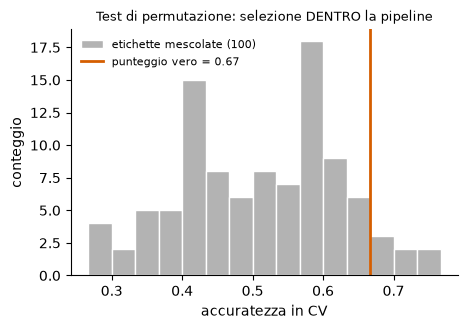

In [11]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
pipe_perm = Pipeline([("selezione", SelectKBest(f_classif, k=10)),
                      ("rf", RandomForestClassifier(n_estimators=100, random_state=0))])
vero, nulli, p_val = permutation_test_score(pipe_perm, Xr, yr, cv=cv5, n_permutations=100,
                                            random_state=0, n_jobs=-1)
print(f"punteggio vero {vero:.2f};  etichette mescolate: {nulli.mean():.2f} ± {nulli.std():.2f};  p = {p_val:.2f}")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.hist(nulli, bins=15, color="0.7", edgecolor="white", label="etichette mescolate (100)")
ax.axvline(vero, color="#D55E00", lw=2, label=f"punteggio vero = {vero:.2f}")
ax.set_xlabel("accuratezza in CV"); ax.set_ylabel("conteggio"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Test di permutazione: selezione DENTRO la pipeline", fontsize=9)
plt.show()

Il punteggio vero (0.67) sembra "sopra il caso", ma cade dentro la distribuzione dei punteggi
ottenuti con etichette mescolate: p ≈ 0.1, cioè circa una permutazione su dieci fa altrettanto
bene per puro caso. Con 30 campioni un 0.6-0.7 su rumore è normale. Confrontate con il
passo 3 sbagliato (0.87): lì nessun test lo avrebbe smascherato, perché la selezione aveva già
visto tutte le etichette.

In sintesi: qualunque operazione che *guarda le etichette* (selezione di variabili, scelta di
parametri, rimozione di "anomali" che stanno nella classe sbagliata), se fatta su tutto il
dataset prima della validazione, **contamina la validazione** e produce risultati falsi. Il
modo per non sbagliare è metterla dentro una `Pipeline`, che la ripete in ogni fold sul
solo train.

Questo vale anche per la standardizzazione e l'imputazione (meno drammatico, ma stesso principio):

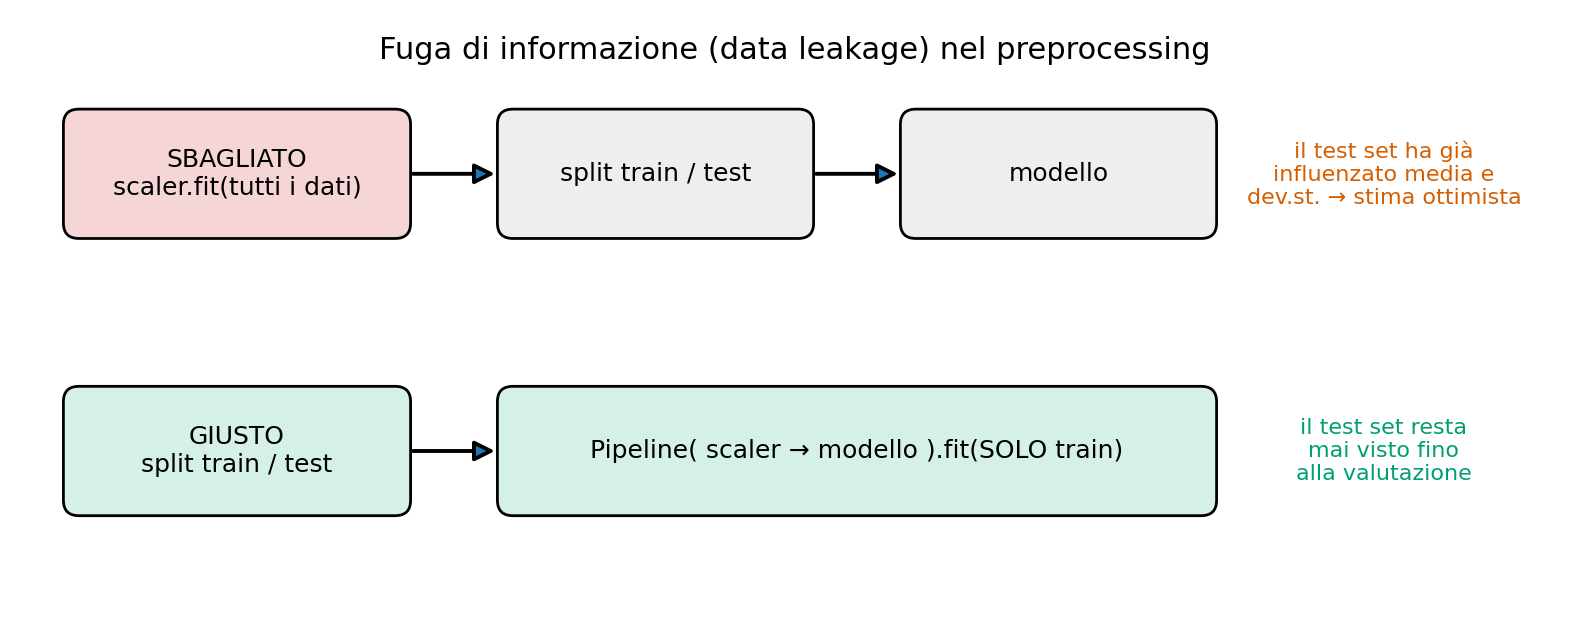

---
## 5. Metriche: oltre l'accuratezza

L'accuratezza (frazione di previsioni giuste) inganna con le classi sbilanciate: se il 90 %
dei campioni è "sano", un modello che dice sempre "sano" ha accuratezza 0.90 e non ha
imparato niente. Guardate sempre la **matrice di confusione**: chi viene scambiato per chi.

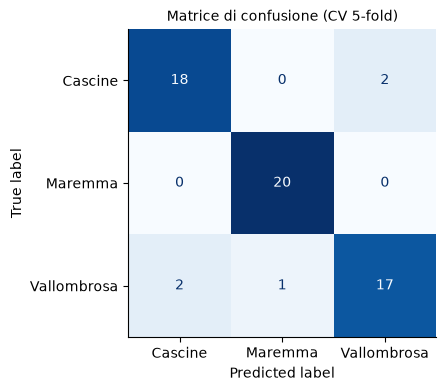

              precision    recall  f1-score   support

     Cascine      0.900     0.900     0.900        20
     Maremma      0.952     1.000     0.976        20
 Vallombrosa      0.895     0.850     0.872        20

    accuracy                          0.917        60
   macro avg      0.916     0.917     0.916        60
weighted avg      0.916     0.917     0.916        60



In [12]:
modello = Pipeline([("imputer", SimpleImputer(strategy="median")),
                    ("rf", RandomForestClassifier(n_estimators=300, random_state=0))])
y_pred_cv = cross_val_predict(modello, X, y, cv=cv)      # previsione di ogni campione quando era nel test

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y, y_pred_cv, ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Matrice di confusione (CV 5-fold)", fontsize=10)
plt.show()
print(classification_report(y, y_pred_cv, digits=3))

Leggete: *precision* = di quelli che ho chiamato "Vallombrosa", quanti lo erano; *recall* =
dei veri "Vallombrosa", quanti ne ho presi. Gli errori stanno quasi tutti fra Cascine e
Vallombrosa, mentre i campioni di Maremma vengono sempre riconosciuti (recall 1.00; uno solo di un
altro sito viene scambiato per Maremma, da cui la precision 0.95): è un'informazione che l'accuratezza da
sola non dà, e coincide con quanto visto nella PCA di stamattina.

---
## 6. `Pipeline` completa e importanza delle variabili

Una `Pipeline` incatena i passi (imputazione → scaling → modello) in un oggetto unico con
`fit` / `predict`. Vantaggi: nessuna fuga di informazione nella CV; un solo oggetto da
salvare e riusare su dati nuovi.

La random forest offre `feature_importances_`: quanto ogni variabile contribuisce alle
decisioni degli alberi. È un'indicazione, non una prova: variabili correlate si dividono
l'importanza, e un'importanza alta non dice *in che direzione*. Per la direzione tornate ai
grafici (box plot per classe) o ai loadings di stamattina.

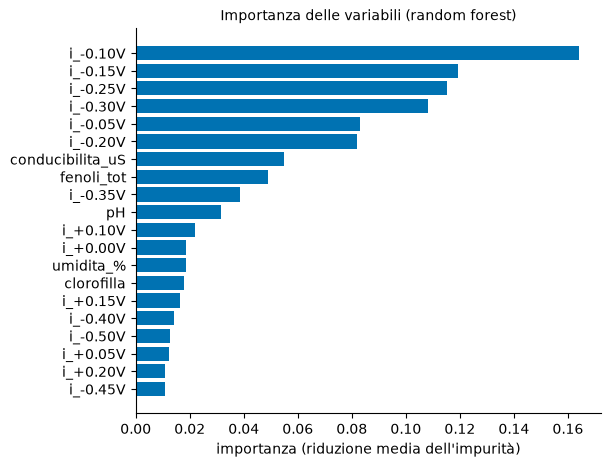

In [13]:
pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                 ("scaler", StandardScaler()),          # non serve alla RF, ma non nuoce e serve ad altri modelli
                 ("rf", RandomForestClassifier(n_estimators=500, random_state=0))])
pipe.fit(X, y)

importanze = pd.Series(pipe.named_steps["rf"].feature_importances_, index=variabili).sort_values()
top3 = importanze.sort_values(ascending=False).head(3).index      # le 3 più importanti (servono più avanti)
fig, ax = plt.subplots(figsize=(6, 5))
ax.barh(importanze.index, importanze.values)
ax.set_xlabel("importanza (riduzione media dell'impurità)")
ax.set_title("Importanza delle variabili (random forest)", fontsize=10)
plt.show()

> *Facoltativo: si può saltare se si è in ritardo (fino a "Usare il modello su un campione nuovo" compreso).*

Attenzione all'importanza "da impurità" (`feature_importances_`): è calcolata sui dati di
addestramento e favorisce le variabili continue con molti valori diversi; con variabili
correlate si divide in modo arbitrario. Un'alternativa più affidabile è l'**importanza per
permutazione** su dati non visti: si rimescola una colonna alla volta nel test set e si misura
quanto peggiora l'accuratezza. Se peggiora, il modello quella variabile la usava davvero.

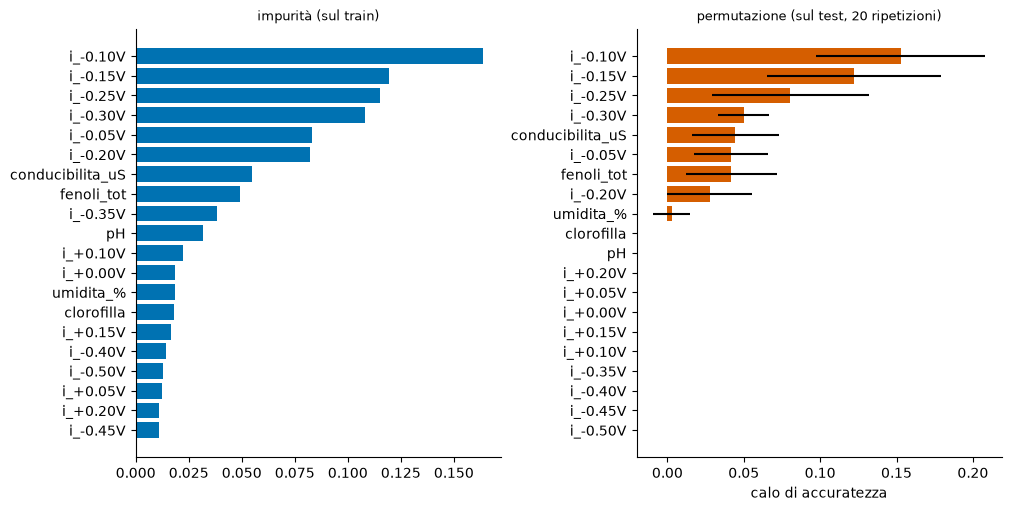

top 5 per impurità:    ['i_-0.10V', 'i_-0.15V', 'i_-0.25V', 'i_-0.30V', 'i_-0.05V']
top 5 per permutazione: ['i_-0.10V', 'i_-0.15V', 'i_-0.25V', 'i_-0.30V', 'conducibilita_uS']


In [14]:
X_a, X_b, y_a, y_b = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
pipe_pi = Pipeline([("imputer", SimpleImputer(strategy="median")),
                    ("rf", RandomForestClassifier(n_estimators=300, random_state=0))]).fit(X_a, y_a)
pi = permutation_importance(pipe_pi, X_b, y_b, n_repeats=20, random_state=0, n_jobs=-1)
imp_perm = pd.Series(pi.importances_mean, index=variabili).sort_values()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 5), sharey=False, constrained_layout=True)
a1.barh(importanze.index, importanze.values); a1.set_title("impurità (sul train)", fontsize=9)
a2.barh(imp_perm.index, imp_perm.values, xerr=pd.Series(pi.importances_std, index=variabili)[imp_perm.index], color="#D55E00")
a2.set_title("permutazione (sul test, 20 ripetizioni)", fontsize=9); a2.set_xlabel("calo di accuratezza")
plt.show()
print("top 5 per impurità:   ", list(importanze.sort_values(ascending=False).head(5).index))
print("top 5 per permutazione:", list(imp_perm.sort_values(ascending=False).head(5).index))

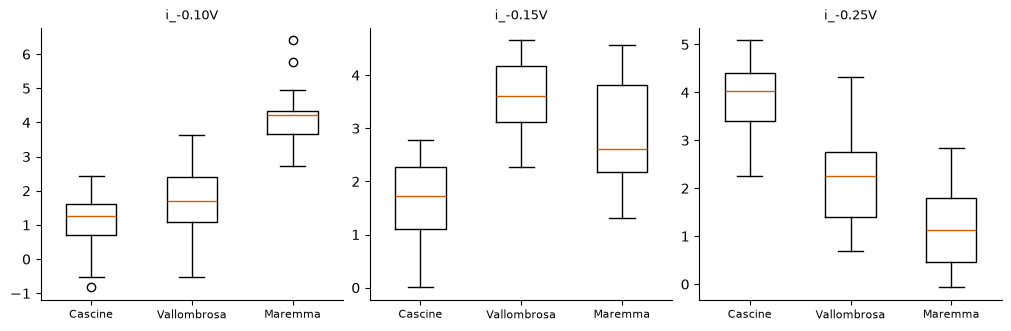

In [15]:
# La direzione: box plot delle 3 variabili più importanti (per impurità), per classe
fig, axs = plt.subplots(1, 3, figsize=(10, 3.2), constrained_layout=True)
for ax, v in zip(axs, top3):
    dati = [df.loc[df["classe"] == cl, v].dropna().values for cl in ["Cascine", "Vallombrosa", "Maremma"]]
    ax.boxplot(dati, positions=range(3), widths=0.5)
    ax.set_xticks(range(3), ["Cascine", "Vallombrosa", "Maremma"], fontsize=8)
    ax.set_title(v, fontsize=9)
plt.show()

### Usare il modello su un campione nuovo

> *Facoltativo: si può saltare se si è in ritardo.*

In [16]:
nuovo = X.iloc[[7]].copy()          # facciamo finta che sia nuovo
nuovo.iloc[0, 3] = np.nan            # con un valore mancante: la pipeline lo gestisce
print("previsione:", pipe.predict(nuovo)[0], "| vero:", y.iloc[7])
print("probabilità per classe:", {cl: round(float(p), 2) for cl, p in zip(pipe.classes_, pipe.predict_proba(nuovo)[0])})

previsione: Maremma | vero: Maremma
probabilità per classe: {'Cascine': 0.01, 'Maremma': 0.94, 'Vallombrosa': 0.05}


---
## 7. Progetto finale (60')

**Dataset: `dati/dataset_features_campioni.csv`.** 36 campioni, ciascuno misurato in **3 repliche**
(108 righe), 45 variabili numeriche (`feature_01` … `feature_45`) e 3 classi (`Classe_A`,
`Classe_B`, `Classe_C`, 12 campioni ciascuna). La domanda: dalle variabili si riconosce la classe
di un campione?

È un **dataset pilota**: pochi campioni, raccolti per esplorare, non per dimostrare. È la situazione
più comune all'inizio di un progetto, e la domanda giusta non è solo "funziona?", ma anche
"**quanto possiamo fidarci di quello che vediamo, e quanti campioni servirebbero per saperlo?**".
Qualunque risultato esca, anche "non si distingue dal caso", è un'informazione utile per pianificare.

**La novità: le repliche.** Le tre repliche di uno stesso campione si somigliano molto più fra
loro che a qualunque altro campione. Se la validazione crociata mette una replica nel train e
un'altra nel test, il modello "riconosce il campione" e non la classe: è la stessa fuga di
informazione della sezione 4, travestita. Il rimedio è dividere per **gruppi**: tutte le
repliche di un campione stanno o tutte nel train o tutte nel test. In scikit-learn:

```python
cv_g = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
cross_val_score(modello, X, y, cv=cv_g, groups=gruppi)     # gruppi = la colonna "campione"
```

È la pseudoreplicazione del giorno 3, vista dal lato del machine learning: l'unità
indipendente è il campione, non la replica.

Da soli o in coppia, consegnate un notebook (o una sezione) che contenga:

1. Caricamento: `X`, `y`, `gruppi`; controllate mancanti, campioni per classe, repliche per
   campione (5').
2. Esplorazione: PCA standardizzata, scores colorati per classe (5').
3. Modello: pipeline imputer → random forest. Validazione crociata a 5 fold **due volte**:
   `StratifiedKFold` (sbagliata: ignora le repliche) e `StratifiedGroupKFold` con
   `groups=campione` (giusta). Media ± sd di entrambe (15').
4. Matrice di confusione con la CV per gruppi (`cross_val_predict(..., groups=...)`) (5').
5. *Facoltativo: si può saltare se si è in ritardo.* Controllo di sanità con un test di
   permutazione, in una cella a parte dopo quella del progetto (15'). Il resto del progetto
   funziona anche senza.
6. Conclusione onesta (10'), 5-8 righe in Markdown: con che accuratezza e incertezza si
   riconoscono le classi, quanti campioni *indipendenti* avete, cosa **non** potete concludere,
   cosa servirebbe per fidarsi di più.

Struttura consigliata:

1) (108, 45) | mancanti: 0
   campioni per classe: {'Classe_A': 12, 'Classe_B': 12, 'Classe_C': 12} | repliche per campione: [3]


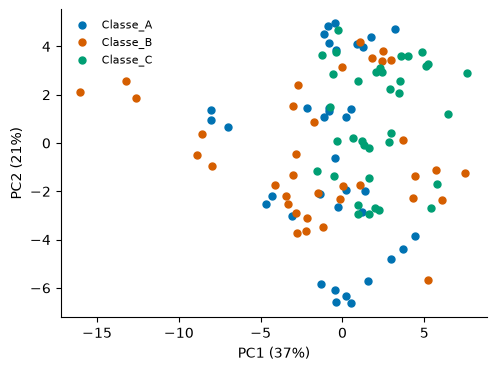

3) CV senza gruppi: 0.645 ± 0.146   <- repliche fra train e test
   CV per campione: 0.437 ± 0.093   (il caso: 0.33)


4)
previsto  Classe_A  Classe_B  Classe_C
vero                                  
Classe_A        14        15         7
Classe_B         7        13        16
Classe_C        10         6        20


In [17]:
# PROGETTO FINALE
FILE = DATI / "dataset_features_campioni.csv"
COL_ID, COL_CLASSE = "campione", "classe"

# 1. carica; X (solo le colonne feature_), y, gruppi; mancanti, campioni per classe, repliche per campione
# 2. PCA (imputer -> scaler -> PCA): scores per classe
# 3. pipeline imputer -> RF; CV senza gruppi (StratifiedKFold) e con gruppi (StratifiedGroupKFold); media ± sd
# 4. matrice di confusione con cross_val_predict(..., cv=cv_g, groups=gruppi)
# 6. conclusione in una cella Markdown sotto (il punto 5, facoltativo, è nella cella dopo)
#
# Traccia: sostituite i ____ (chi vuole una sfida cancelli la traccia e scriva da zero).
#> from sklearn.decomposition import PCA
#> d = pd.read_csv(FILE)
#> cols = [c for c in d.columns if c.startswith(____)]
#> Xp, yp, gruppi = d[cols], d[COL_CLASSE], d[____]
#> print("1)", Xp.shape, "| mancanti:", int(Xp.isna().sum().sum()))
#> print("   campioni per classe:", d.groupby(COL_CLASSE)[COL_ID].____().to_dict(),
#>       "| repliche per campione:", gruppi.value_counts().unique())
#>
#> # 2) PCA: prima imputer e scaler (come stamattina), poi gli scores colorati per classe
#> pre = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", ____)])
#> Z = pre.fit_transform(Xp)
#> pca = PCA().fit(Z); S = pca.transform(Z)
#> fig, ax = plt.subplots(figsize=(5.5, 4))
#> for cl in sorted(yp.unique()):
#>     ax.plot(S[yp == cl, 0], S[yp == cl, 1], "o", ms=5, label=cl)
#> ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(frameon=False, fontsize=8)
#> plt.show()
#>
#> # 3) la stessa pipeline, valutata con due CV diverse
#> pipe_f = Pipeline([("imputer", SimpleImputer(strategy="median")),
#>                    ("rf", RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1))])
#> cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
#> cv_g = ____(n_splits=5, shuffle=True, random_state=0)
#> sc_n = cross_val_score(pipe_f, Xp, yp, cv=cv_n)
#> sc_g = cross_val_score(pipe_f, Xp, yp, cv=cv_g, groups=____)
#> print(f"3) CV senza gruppi: {sc_n.mean():.3f} ± {sc_n.std():.3f}")
#> print(f"   CV per campione: {sc_g.mean():.3f} ± {sc_g.std():.3f}   (il caso: {1/yp.nunique():.2f})")
#>
#> # 4) matrice di confusione con la CV per gruppi
#> pred = cross_val_predict(pipe_f, Xp, yp, cv=____, groups=gruppi)
#> print(pd.crosstab(yp, pred, rownames=["vero"], colnames=["previsto"]))
# --- SOLUZIONE ---
from sklearn.decomposition import PCA
d = pd.read_csv(FILE)
cols = [c for c in d.columns if c.startswith("feature_")]
Xp, yp, gruppi = d[cols], d[COL_CLASSE], d[COL_ID]
print("1)", Xp.shape, "| mancanti:", int(Xp.isna().sum().sum()))
print("   campioni per classe:", d.groupby(COL_CLASSE)[COL_ID].nunique().to_dict(),
      "| repliche per campione:", gruppi.value_counts().unique())

pre = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
pca = PCA().fit(pre.fit_transform(Xp)); S = pca.transform(pre.transform(Xp))
fig, ax = plt.subplots(figsize=(5.5, 4))
for cl in sorted(yp.unique()):
    ax.plot(S[yp == cl, 0], S[yp == cl, 1], "o", ms=5, label=cl)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend(frameon=False, fontsize=8)
plt.show()

pipe_f = Pipeline([("imputer", SimpleImputer(strategy="median")),
                   ("rf", RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1))])
cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_g = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
sc_n = cross_val_score(pipe_f, Xp, yp, cv=cv_n)
sc_g = cross_val_score(pipe_f, Xp, yp, cv=cv_g, groups=gruppi)
print(f"3) CV senza gruppi: {sc_n.mean():.3f} ± {sc_n.std():.3f}   <- repliche fra train e test")
print(f"   CV per campione: {sc_g.mean():.3f} ± {sc_g.std():.3f}   (il caso: {1/yp.nunique():.2f})")

pred = cross_val_predict(pipe_f, Xp, yp, cv=cv_g, groups=gruppi)
print("4)"); print(pd.crosstab(yp, pred, rownames=["vero"], colnames=["previsto"]))

**5) Facoltativo: test di permutazione.** Si può saltare se si è in ritardo.

Le etichette vanno mescolate **fra campioni**, non fra righe: le tre repliche restano con la
stessa classe. La funzione qui sotto è già pronta. Confrontate il punteggio vero con la
distribuzione dei mescolati, con la CV per gruppi e con quella senza gruppi.

Il calcolo rifà la CV 50 volte per ciascuna delle due versioni: su un portatile può richiedere
alcuni minuti. Se è lento, usate `n=20`: la conclusione non cambia. Per velocità qui la random
forest ha 100 alberi invece di 300, quindi il punteggio "vero" esce leggermente diverso da quello
del punto 3 (0.42 contro 0.44): è normale, conta il confronto con i mescolati fatto con lo stesso modello.

5) CV per campione: vero 0.415; mescolati 0.340 ± 0.083; p = 0.25
   CV senza gruppi, classi mescolate: 0.621 ± 0.051   <- 'impara' anche senza classi vere


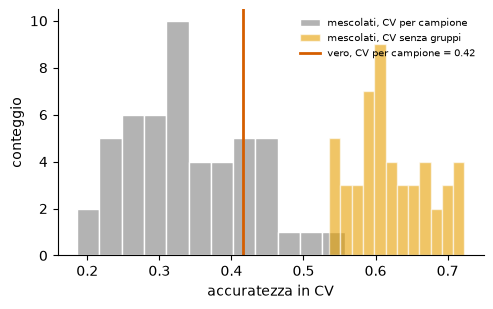

In [18]:
# PROGETTO FINALE, punto 5 (facoltativo)
def permutazioni_per_campione(modello, X, y, gruppi, cv, usa_gruppi=True, n=50, seme=0):
    """Accuratezza in CV con le classi mescolate FRA CAMPIONI (le repliche restano insieme).
    usa_gruppi=False per una CV che non conosce i gruppi (StratifiedKFold).
    Restituisce un array di n punteggi: la distribuzione "a etichette casuali"."""
    rng = np.random.default_rng(seme)
    classe_campione = y.groupby(gruppi).first()
    punteggi = []
    for _ in range(n):
        mescolate = dict(zip(classe_campione.index, rng.permutation(classe_campione.values)))
        y_mescolata = gruppi.map(mescolate)
        punteggi.append(cross_val_score(modello, X, y_mescolata, cv=cv,
                                         groups=gruppi if usa_gruppi else None).mean())
    return np.array(punteggi)

# 5. permutazioni_per_campione(...) con cv_g e con cv_n (usa_gruppi=False);
#    p-value = (1 + quanti mescolati >= vero) / (n + 1)
# --- SOLUZIONE ---
pipe_veloce = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("rf", RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1))])
vero_g = cross_val_score(pipe_veloce, Xp, yp, cv=cv_g, groups=gruppi).mean()
nulli_g = permutazioni_per_campione(pipe_veloce, Xp, yp, gruppi, cv_g)
nulli_n = permutazioni_per_campione(pipe_veloce, Xp, yp, gruppi, cv_n, usa_gruppi=False)
p_g = (1 + (nulli_g >= vero_g).sum()) / (len(nulli_g) + 1)
print(f"5) CV per campione: vero {vero_g:.3f}; mescolati {nulli_g.mean():.3f} ± {nulli_g.std():.3f}; p = {p_g:.2f}")
print(f"   CV senza gruppi, classi mescolate: {nulli_n.mean():.3f} ± {nulli_n.std():.3f}   <- 'impara' anche senza classi vere")

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.hist(nulli_g, bins=12, color="0.7", edgecolor="white", label="mescolati, CV per campione")
ax.hist(nulli_n, bins=12, color="#E69F00", alpha=0.6, edgecolor="white", label="mescolati, CV senza gruppi")
ax.axvline(vero_g, color="#D55E00", lw=2, label=f"vero, CV per campione = {vero_g:.2f}")
ax.set_xlabel("accuratezza in CV"); ax.set_ylabel("conteggio"); ax.legend(frameon=False, fontsize=7)
plt.show()

**6) Conclusione.** Scrivetela in una cella Markdown qui sotto, in tre o quattro frasi: quale
accuratezza riportate e con quale validazione, come si confronta con il caso, quale dei due
numeri non va usato e perché, cosa servirebbe per rispondere meglio alla domanda.

> Estensioni facoltative: (1) fate la media delle 3 repliche per campione (`groupby` sul campione,
> 36 righe) e rifate la CV normale: torna un numero simile alla CV per gruppi? (2) importanza
> delle variabili: alla luce del vostro risultato, ha senso guardarla? (3) provate un
> secondo modello (`LogisticRegression` con scaler) con la CV per gruppi.

**6) Conclusione** (un esempio di come può essere scritta):

> Con la validazione per campione (5 fold, le repliche di un campione sempre dalla stessa parte)
> l'accuratezza è 0.44 ± 0.09, contro 0.33 attesa per il caso, su 36 campioni indipendenti
> (108 misure). Il test di permutazione (punto 5) con le classi mescolate fra campioni dà
> p ≈ 0.25: con questi numeri il risultato non si distingue ancora dal caso. Classe_C è riconosciuta un po'
> meglio (20 misure su 36); Classe_A e Classe_B si confondono di più.
> La validazione che ignora le repliche dà 0.65 ± 0.15, ma arriva a 0.62 anche con le classi
> mescolate (punto 5): quel numero misura soprattutto quanto si somigliano le repliche di uno stesso
> campione, quindi non va usato per giudicare il modello.
> La domanda resta aperta: 12 campioni per classe sono pochi per vedere un effetto moderato,
> e le repliche non contano come campioni nuovi. Per rispondere servirebbero più campioni
> indipendenti per classe e, idealmente, un gruppo di campioni tenuto da parte come test finale.

#### Nota per il docente: come presentare il risultato

Chi ha fornito i dati è in aula. Il messaggio è sul **metodo**, non sui dati:
- presentate la CV senza gruppi come l'errore che fanno *tutti* la prima volta (è il default di
  ogni tutorial), non come un errore di qualcuno;
- "non distinguibile dal caso con 36 campioni" non vuol dire "le variabili non servono": vuol dire
  che la domanda richiede più campioni indipendenti. È un risultato utile per pianificare;
- se chi ha fornito i dati vuole intervenire, è il momento giusto: sa meglio di tutti quali
  variabili *dovrebbero* contare, ed è l'ipotesi da verificare sul prossimo lotto di campioni.
- I numeri sono stati trasformati colonna per colonna (scala e spostamento casuali, colonne e
  campioni rimescolati): non corrispondono a misure reali, ma le analisi danno gli stessi risultati.

---
## 8. Chiusura del corso (15')

### Cosa fare la settimana prossima

1. Riaprite un notebook del corso e rieseguitelo da capo (*Restart & Run All*). Se gira,
   l'ambiente è a posto.
2. Prendete un vostro file reale e rifate il progetto del giorno 2 (pulizia + report). È
   l'esercizio più utile che possiate fare.
3. Rifate una vostra figura con `figure_pubblicazione.py`. Confrontatela con
   l'originale in scala di grigi.

### Python e R: cosa farete con cosa? (5', discussione)

Riprendiamo la tabella del primo giorno. Ognuno pensi al proprio lavoro: quali passaggi farebbe
in Python (procurarsi e unire i dati, pulizia ripetuta, automazione, ML, figure in serie) e quali
resteranno in R (modelli statistici, Bioconductor)? Le due cose convivono: un CSV scritto da pandas
si legge in R con `read.csv`, e viceversa.

### Dove cercare (tutto libero, CC-BY)

- Software Carpentry, *Plotting and Programming in Python*: per ripassare le basi.
- Aalto Scientific Computing, *Python for Scientific Computing*: pandas, NumPy, buone pratiche.
- Scientific Python Lectures (lectures.scientific-python.org): SciPy, statistica, scikit-learn.
- La documentazione ufficiale di pandas ("10 minutes to pandas"), Matplotlib (galleria degli
  esempi: cercate la figura simile e copiate il codice), scikit-learn (*User Guide*, non l'API).
- La scheda `personalizzazione_grafici.ipynb` e il modulo `figure_pubblicazione.py`.

### Gli errori tipici della prima settimana da soli

| Sintomo | Probabile causa |
|---|---|
| `FileNotFoundError` | Python cerca nella cartella sbagliata: `Path.cwd()`, percorsi relativi |
| `NameError` | cella non eseguita, kernel riavviato |
| `read_csv` dà una colonna sola, o numeri come testo | `sep`, `decimal`, `encoding` |
| Il merge raddoppia le righe | chiave non univoca |
| La PCA "dice" solo una variabile | non avete standardizzato |
| Accuratezza 100 % | avete valutato sul train, o l'etichetta è finita in `X`, o selezione fuori dalla CV |

### Assistenti automatici per il codice

Non li abbiamo usati, di proposito. Ora però avete l'unica cosa che serve per usarli bene:
saper leggere il codice che producono e verificarlo, con un test piccolo, un output
atteso, un grafico di controllo. Un assistente che vi scrive `read_csv` con i parametri
giusti vi fa risparmiare cinque minuti; uno che vi scrive una CV con la selezione fuori dalla
pipeline vi fa pubblicare un risultato falso, e lo fa con molta sicurezza. Usateli come un
collega veloce e distratto: utile, mai da fidarsi sulla parola.

---
Grazie. In questi quattro giorni avete scritto codice che legge file, pulisce dati, fa figure
da rivista, rette di taratura con le incertezze, PCA e un classificatore validato.

---
## Esercizi per casa (facoltativi)

### Esercizio C8.1: quanti campioni servono perché l'inganno smetta di funzionare? (livello 2)

Ripetete il "passo 3 sbagliato" (selezione delle 10 variabili più correlate su tutto il
dataset, poi CV) su rumore puro con n = 30, 100, 300, 1000 campioni (generateli:
`rng.normal(size=(n, 200))`, etichette `rng.integers(0, 2, n)`). Il risultato di un singolo
dataset è molto variabile: ripetete per 5 dataset diversi a ogni n e fate la media. Con quanti
campioni l'accuratezza falsa torna vicina a 0.5? Fate un grafico accuratezza-falsa vs n.

n =    30: accuratezza 'ottenuta' = 0.75 ± 0.03  (5 dataset)


n =   100: accuratezza 'ottenuta' = 0.71 ± 0.04  (5 dataset)


n =   300: accuratezza 'ottenuta' = 0.61 ± 0.03  (5 dataset)


n =  1000: accuratezza 'ottenuta' = 0.54 ± 0.01  (5 dataset)


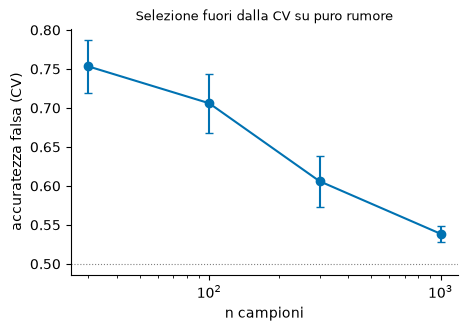

In [19]:
# ESERCIZIO C8.1 (livello 2)
rng = np.random.default_rng(0)
# per ogni n, per 5 dataset: genera X, y casuali; seleziona le 10 variabili più correlate su tutto; CV; media
# --- SOLUZIONE ---
ns = [30, 100, 300, 1000]
falsa, falsa_sd = [], []
for n in ns:
    ripetizioni = []
    for _ in range(5):
        Xn = pd.DataFrame(rng.normal(size=(n, 200)))
        yn = pd.Series(rng.integers(0, 2, n))
        top = Xn.corrwith(yn).abs().sort_values(ascending=False).head(10).index
        ripetizioni.append(cross_val_score(RandomForestClassifier(n_estimators=50, random_state=0, n_jobs=-1),
                                           Xn[top], yn, cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean())
    falsa.append(np.mean(ripetizioni)); falsa_sd.append(np.std(ripetizioni))
    print(f"n = {n:5d}: accuratezza 'ottenuta' = {falsa[-1]:.2f} ± {falsa_sd[-1]:.2f}  (5 dataset)")
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.errorbar(ns, falsa, yerr=falsa_sd, fmt="o-", capsize=3); ax.axhline(0.5, color="gray", ls=":", lw=0.8)
ax.set_xscale("log"); ax.set_xlabel("n campioni"); ax.set_ylabel("accuratezza falsa (CV)")
ax.set_title("Selezione fuori dalla CV su puro rumore", fontsize=9)
plt.show()

### Esercizio C8.2: il modello regge con meno variabili? (livello 2)

Un sensore che deve leggere 15 potenziali è più lento e costoso di uno che ne legge 3.
Valutate in CV (5-fold, stessa `cv`) la pipeline usando:
1. tutte le 20 variabili;
2. solo le 15 correnti;
3. solo le 5 chimico-fisiche;
4. le 3 variabili più importanti (`top3`). Attenzione: `top3` è stata scelta guardando tutto
   il dataset. È un problema? Quanto, qui? Scrivetelo in un commento.

Stampate media ± sd per ciascun caso.

In [20]:
# ESERCIZIO C8.2 (livello 2)
correnti = [c for c in variabili if c.startswith("i_")]
chimfis = [c for c in variabili if not c.startswith("i_")]
insiemi = {"tutte (20)": variabili, "correnti (15)": correnti, "chimico-fisiche (5)": chimfis, "top3 (scelte su tutto)": list(top3)}
# per ogni insieme: cross_val_score(pipe, X[cols], y, cv=cv)
# --- SOLUZIONE ---
for nome, cols in insiemi.items():
    p = cross_val_score(pipe, X[cols], y, cv=cv)
    print(f"{nome:26s}: {p.mean():.3f} ± {p.std():.3f}")
# Commento: top3 è stata selezionata con le etichette di TUTTO il dataset, quindi la sua CV è
# leggermente ottimista. Con 3 variabili su 20 e 60 campioni l'effetto è piccolo (non siamo nel
# caso 200 variabili / 30 campioni), ma per una stima corretta la selezione va messa dentro la pipeline.

tutte (20)                : 0.917 ± 0.091


correnti (15)             : 0.917 ± 0.129


chimico-fisiche (5)       : 0.700 ± 0.135


top3 (scelte su tutto)    : 0.917 ± 0.075


---
*Materiali del corso rilasciati con licenza CC-BY 4.0. Contenuti ispirati a Software Carpentry,
Aalto Scientific Computing e Scientific Python Lectures (tutti CC-BY 4.0).*